# Two seasons on one xG model (Understat)

StatsBomb's free data covers 2015/16 only. [Understat](https://understat.com) published xG for **every Premier League shot from 2014/15**,
so Pearson's season and Ranieri's season can be compared shot by shot, on the same model.

**Data:** Understat shot and player data, from the public copy at
[douglasbc/scraping-understat-dataset](https://github.com/douglasbc/scraping-understat-dataset) (Understat's own site was offline when this was built).
Download with `python -m football_analytics.understat 14-15 15-16` from the repo root.

**Checks:** all 380 matches in both seasons; Leicester's goals for and against match the official results (46–55 and 68–36).

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mplsoccer import VerticalPitch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # project folder
REPO = next(p for p in [ROOT, *ROOT.parents] if (p / "src" / "football_analytics").exists())  # repo root: shared code and downloaded data
sys.path.insert(0, str(REPO / "src"))
from football_analytics.viz import leaderboard

U = REPO / "data" / "raw" / "understat"
FIGS = ROOT / "reports" / "figures"
LEI = "Leicester"
BLUE, GREY, DARK, MUTED, GOLD = "#1F5FAD", "#B4B2A9", "#3D3D3A", "#6B6A64", "#FDBE11"
GOLD_TEXT = "#9A7200"  # darker gold for text on white
SOURCE = "Data: Understat (via douglasbc/scraping-understat-dataset)"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
    "axes.grid": True, "grid.color": "#ECEAE4", "grid.linewidth": 0.8, "axes.axisbelow": True,
})

SEASONS = {"2014/15": "14-15", "2015/16": "15-16"}
shots, players = {}, {}
for label, s in SEASONS.items():
    d = pd.read_csv(U / f"shots_epl_{s}.csv")
    d["team"] = np.where(d.h_a == "h", d.h_team, d.a_team)
    d["opp"] = np.where(d.h_a == "h", d.a_team, d.h_team)
    d["goal"] = d.result == "Goal"
    d["date"] = pd.to_datetime(d.date)
    shots[label] = d
    players[label] = pd.read_csv(U / f"players_epl_{s}.csv")
    print(label, len(d), "shots,", d.match_id.nunique(), "matches")

2014/15 9914 shots, 380 matches
2015/16 9819 shots, 380 matches


## 1. Expected points, both seasons

Same method as notebook 02: every match replayed 10,000 times, each shot scoring with probability equal to its Understat xG.

In [2]:
rng = np.random.default_rng(42)
def season_table(sh):
    rows = []
    for mid, g in sh.groupby("match_id"):
        h, a = g.h_team.iloc[0], g.a_team.iloc[0]
        hg, ag = g.h_goals.iloc[0], g.a_goals.iloc[0]
        hx, ax_ = g[g.team == h].xG.values, g[g.team == a].xG.values
        hs = (rng.random((10000, len(hx))) < hx).sum(1)
        as_ = (rng.random((10000, len(ax_))) < ax_).sum(1)
        hp = np.where(hs > as_, 3, np.where(hs == as_, 1, 0)).mean()
        ap = np.where(as_ > hs, 3, np.where(hs == as_, 1, 0)).mean()
        rows += [(h, hx.sum(), ax_.sum(), hp, 3 if hg > ag else int(hg == ag)),
                 (a, ax_.sum(), hx.sum(), ap, 3 if ag > hg else int(hg == ag))]
    t = pd.DataFrame(rows, columns=["team", "xG", "xGA", "xPts", "Pts"]).groupby("team").sum()
    t["xG diff"] = t.xG - t.xGA
    for c in ["xPts", "Pts", "xG diff"]:
        t[c + " rank"] = t[c].rank(ascending=False, method="min").astype(int)
    return t.sort_values("xPts", ascending=False)

tables = {k: season_table(v) for k, v in shots.items()}
pd.concat({k: t.loc[LEI] for k, t in tables.items()}, axis=1).round(1)

,2014/15,2015/16
xG,48.6,69.4
xGA,57.8,45.7
xPts,44.3,68.6
Pts,41.0,81.0
xG diff,-9.2,23.7
xPts rank,15.0,4.0
Pts rank,14.0,1.0
xG diff rank,11.0,4.0


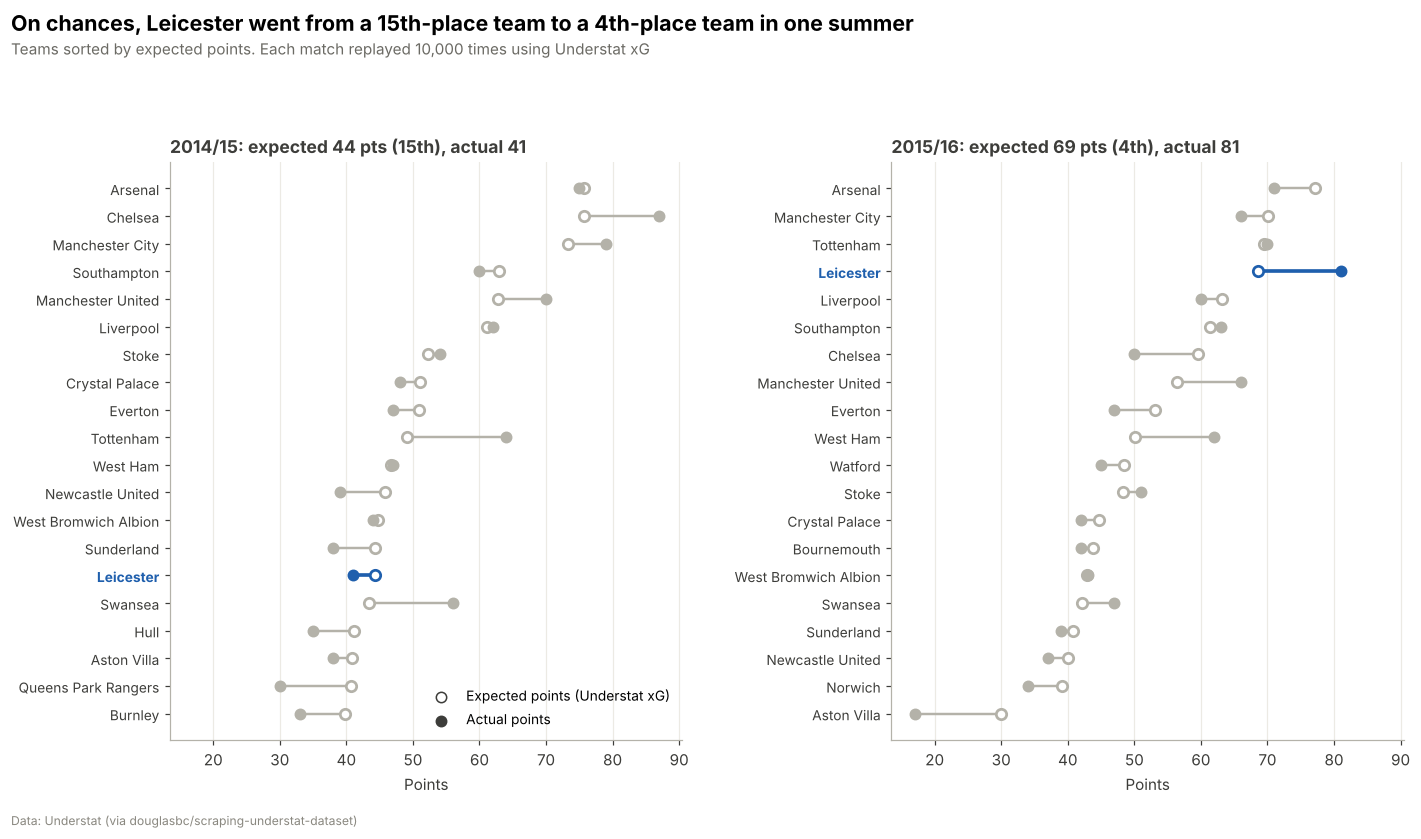

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.8), sharex=True)
for ax, (label, t) in zip(axes, tables.items()):
    t = t.sort_values("xPts")
    y = np.arange(len(t))
    for yi, (team, r) in zip(y, t.iterrows()):
        c = BLUE if team == LEI else GREY
        ax.plot([r.xPts, r.Pts], [yi, yi], color=c, lw=2.4 if team == LEI else 1.6, zorder=1)
        ax.scatter(r.xPts, yi, s=46, facecolor="white", edgecolor=c, lw=1.8, zorder=3)
        ax.scatter(r.Pts, yi, s=46, color=c, zorder=3)
    ax.set_yticks(y, t.index, fontsize=9)
    for tl in ax.get_yticklabels():
        if tl.get_text() == LEI:
            tl.set_color(BLUE); tl.set_fontweight("bold")
    r = t.loc[LEI]
    ax.set_title(f"{label}: expected {r.xPts:.0f} pts ({int(r['xPts rank'])}th), actual {int(r.Pts)}",
                 fontsize=11.5, color=DARK)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Points")
axes[0].scatter([], [], s=46, facecolor="white", edgecolor=DARK, label="Expected points (Understat xG)")
axes[0].scatter([], [], s=46, color=DARK, label="Actual points")
axes[0].legend(loc="lower right", frameon=False, fontsize=9)
fig.suptitle("On chances, Leicester went from a 15th-place team to a 4th-place team in one summer",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.035, va="bottom")
fig.text(0.01, 1.03, "Teams sorted by expected points. Each match replayed 10,000 times using Understat xG",
         fontsize=10, color=MUTED, va="top")
fig.tight_layout(rect=(0, 0, 1, 0.98), w_pad=3)
fig.text(0.01, -0.02, SOURCE, fontsize=8, color="#8A8880")
fig.savefig(FIGS / "24_expected_points_both_seasons.png"); plt.show()

**Reading it:**
- **2014/15:** Leicester's chances were worth about 44 points, **15th-best**. They took 41 and finished 14th, roughly what their chances deserved.
- **2015/16:** their chances were worth about 69 points, **4th-best**, almost exactly what our StatsBomb model said (66, also 4th). They took 81.
- **Two parts to the leap:**
  - About **+24 expected points** of real improvement in the chances they created and allowed.
  - About **+12 points** of overperformance on top of that (explained under chart 02 in the report).

## 2. 76 matches in one line: Pearson to Ranieri

Rolling 10-match average of xG created and xG conceded per match, across both seasons.

In [4]:
rows = []
for label, sh in shots.items():
    lm = sh[(sh.h_team == LEI) | (sh.a_team == LEI)]
    for mid, g in lm.groupby("match_id"):
        rows.append({"season": label, "date": g.date.iloc[0], "xG": g[g.team == LEI].xG.sum(),
                     "xGA": g[g.team != LEI].xG.sum()})
tl = pd.DataFrame(rows).sort_values("date").reset_index(drop=True)
tl["n"] = tl.index + 1
tl["xG_r"] = tl.xG.rolling(10).mean()
tl["xGA_r"] = tl.xGA.rolling(10).mean()
run_start = int(tl[(tl.season == "2014/15") & (tl.date >= "2015-04-04")].n.iloc[0])
jan = int(tl[tl.season == "2015/16"].n.iloc[19])
tl.groupby("season")[["xG", "xGA"]].mean().round(2)

,xG,xGA
season,,
2014/15,1.28,1.52
2015/16,1.83,1.20


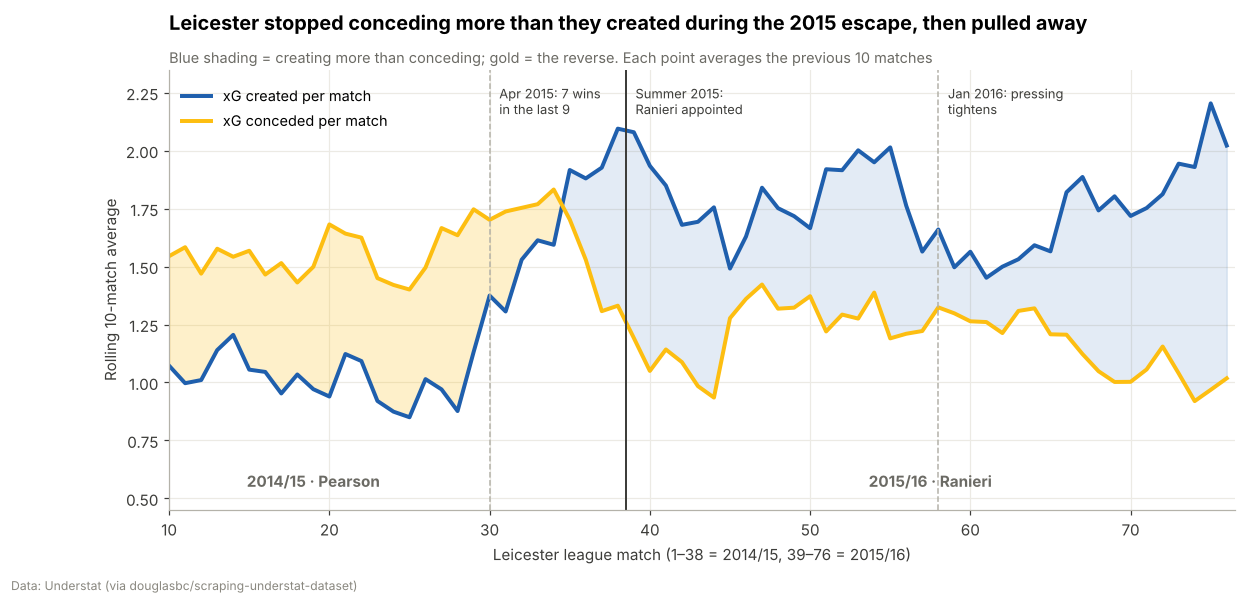

In [5]:
fig, ax = plt.subplots(figsize=(12.5, 5.2))
x, a, b = tl.n.values, tl.xG_r.values, tl.xGA_r.values
ax.fill_between(x, a, b, where=a >= b, color=BLUE, alpha=0.12, interpolate=True)
ax.fill_between(x, a, b, where=a < b, color=GOLD, alpha=0.22, interpolate=True)
ax.plot(x, a, color=BLUE, lw=2.6, label="xG created per match")
ax.plot(x, b, color=GOLD, lw=2.6, label="xG conceded per match")
ax.axvline(38.5, color=DARK, lw=1.2)
for xv, txt in [(run_start, "Apr 2015: 7 wins\nin the last 9"), (38.5, "Summer 2015:\nRanieri appointed"),
                (jan, "Jan 2016: pressing\ntightens")]:
    ax.axvline(xv, color=DARK if xv == 38.5 else GREY, lw=1.2 if xv == 38.5 else 1, ls="-" if xv == 38.5 else "--")
    ax.text(xv + 0.6, 2.28, txt, fontsize=8.5, color=DARK, va="top")
ax.text(19, 0.55, "2014/15 · Pearson", ha="center", fontsize=10, color=MUTED, fontweight="bold")
ax.text(57.5, 0.55, "2015/16 · Ranieri", ha="center", fontsize=10, color=MUTED, fontweight="bold")
ax.set_xlim(10, 76.5); ax.set_ylim(0.45, 2.35)
ax.set_xlabel("Leicester league match (1–38 = 2014/15, 39–76 = 2015/16)")
ax.set_ylabel("Rolling 10-match average")
ax.legend(loc="upper left", frameon=False, ncol=1, fontsize=9.5, bbox_to_anchor=(0, 0.99))
ax.set_title("Leicester stopped conceding more than they created during the 2015 escape, then pulled away", pad=26)
ax.annotate("Blue shading = creating more than conceding; gold = the reverse. Each point averages the previous 10 matches",
            xy=(0, 1.015), xycoords="axes fraction", fontsize=9.5, color=MUTED)
fig.text(0.01, -0.03, SOURCE, fontsize=8, color="#8A8880")
fig.savefig(FIGS / "25_xg_timeline_two_seasons.png"); plt.show()

## 3. Vardy's shots, before and after

Same xG model in both seasons, so the shot maps are directly comparable.

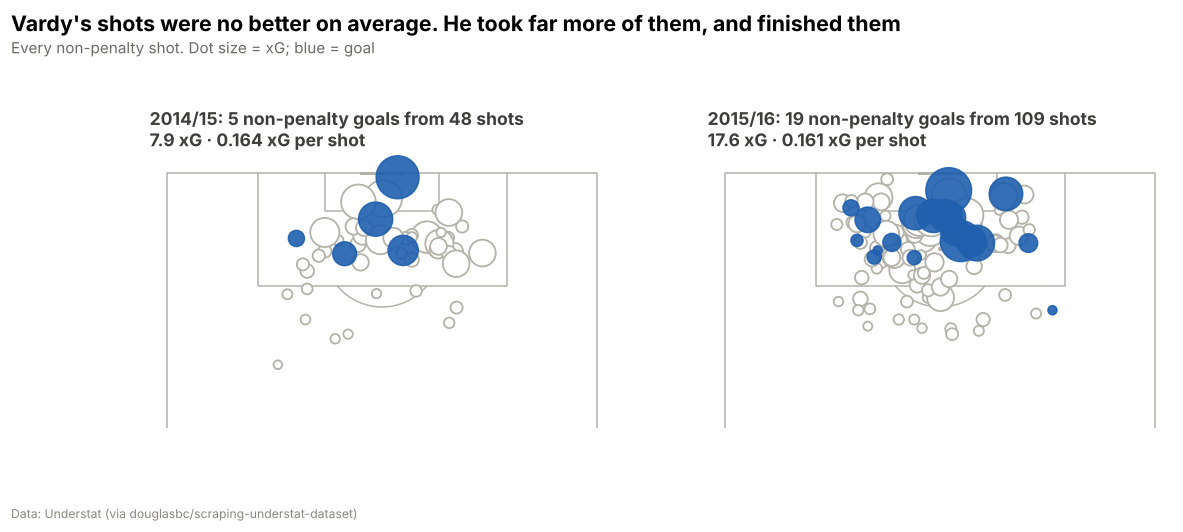

,2014/15,2015/16
shots,48.000,109.000
goals,5.000,19.000
xG,7.852,17.568
xG per shot,0.164,0.161


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.0))
pitch = VerticalPitch(pitch_type="opta", half=True, line_color=GREY, linewidth=1, pad_bottom=-18)
summary = {}
for ax, (label, sh) in zip(axes, shots.items()):
    v = sh[(sh.player == "Jamie Vardy") & (sh.situation != "Penalty")]
    pitch.draw(ax=ax)
    miss = v[~v.goal]; goal = v[v.goal]
    pitch.scatter(miss.X * 100, miss.Y * 100, s=miss.xG * 900 + 20, ax=ax, facecolor="white", edgecolor=GREY, lw=1.2)
    pitch.scatter(goal.X * 100, goal.Y * 100, s=goal.xG * 900 + 20, ax=ax, color=BLUE, alpha=0.9)
    summary[label] = (len(v), int(v.goal.sum()), v.xG.sum(), v.xG.mean())
    n, g, xg, xps = summary[label]
    ax.set_title(f"{label}: {g} non-penalty goals from {n} shots\n{xg:.1f} xG · {xps:.3f} xG per shot",
                 fontsize=11.5, color=DARK)
fig.suptitle("Vardy's shots were no better on average. He took far more of them, and finished them", x=0.02, ha="left",
             fontsize=14, fontweight="bold", y=1.075, va="bottom")
fig.text(0.02, 1.07, "Every non-penalty shot. Dot size = xG; blue = goal", fontsize=10, color=MUTED, va="top")
fig.text(0.02, -0.02, SOURCE, fontsize=8, color="#8A8880")
fig.savefig(FIGS / "26_vardy_shots_two_seasons.png"); plt.show()
pd.DataFrame(summary, index=["shots", "goals", "xG", "xG per shot"]).round(3)

## 4. Where Leicester's chances came from

xG per match by situation, created and conceded. "Set pieces" combines indirect set pieces and direct free kicks.

In [7]:
SIT = {"OpenPlay": "Open play", "FromCorner": "Corners", "SetPiece": "Set pieces", "DirectFreekick": "Set pieces",
       "Penalty": "Penalties"}
rows = []
for label, sh in shots.items():
    lm = sh[(sh.h_team == LEI) | (sh.a_team == LEI)].assign(sit=lambda d: d.situation.map(SIT))
    for side, mask in [("Created", lm.team == LEI), ("Conceded", lm.team != LEI)]:
        g = lm[mask].groupby("sit").xG.sum() / 38
        for k, v in g.items():
            rows.append((label, side, k, v))
sit = pd.DataFrame(rows, columns=["season", "side", "situation", "xG_pg"])
piv = sit.pivot_table(index=["side", "situation"], columns="season", values="xG_pg").round(3)
piv["change"] = (piv["2015/16"] - piv["2014/15"]).round(3)
piv

season               2014/15  2015/16  change
side     situation                           
Conceded Corners       0.270    0.256  -0.014
         Open play     1.021    0.805  -0.216
         Penalties     0.080    0.080   0.000
         Set pieces    0.150    0.062  -0.088
Created  Corners       0.133    0.188   0.055
         Open play     0.933    1.266   0.333
         Penalties     0.080    0.260   0.180
         Set pieces    0.131    0.114  -0.017

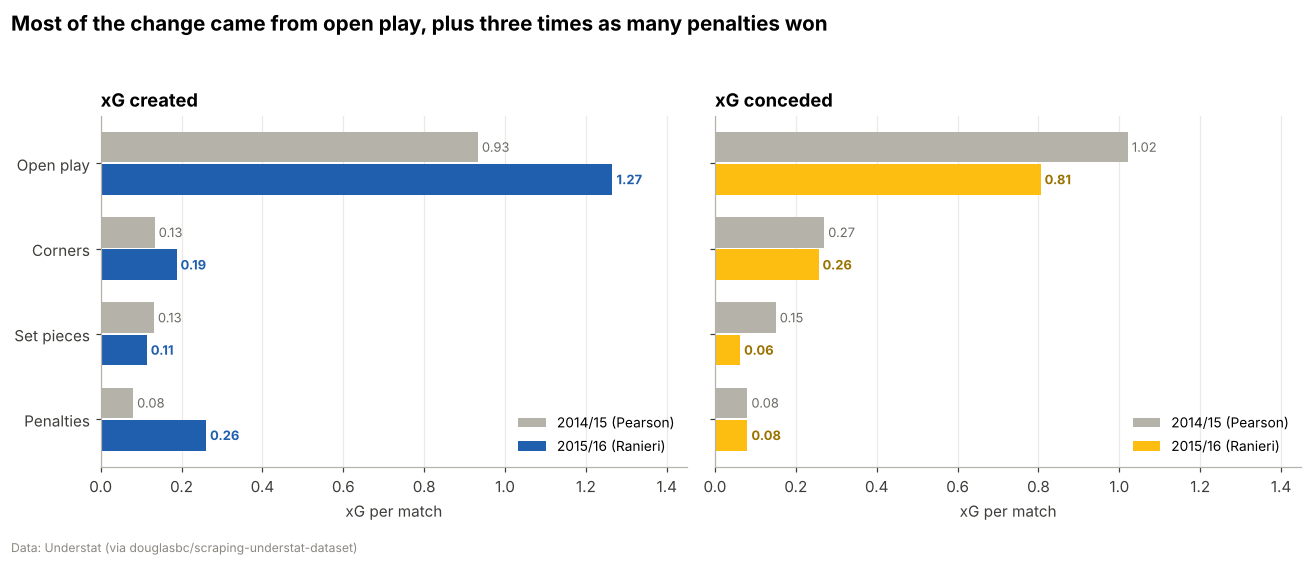

In [8]:
order = ["Open play", "Corners", "Set pieces", "Penalties"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, side in zip(axes, ["Created", "Conceded"]):
    d = sit[sit.side == side].pivot(index="situation", columns="season", values="xG_pg").reindex(order)
    y = np.arange(len(order))[::-1]
    ax.barh(y + 0.19, d["2014/15"], height=0.36, color=GREY, label="2014/15 (Pearson)")
    ax.barh(y - 0.19, d["2015/16"], height=0.36, color=BLUE if side == "Created" else GOLD, label="2015/16 (Ranieri)")
    for yi, a, b in zip(y, d["2014/15"], d["2015/16"]):
        ax.text(a + 0.01, yi + 0.19, f"{a:.2f}", va="center", fontsize=8.5, color=MUTED)
        ax.text(b + 0.01, yi - 0.19, f"{b:.2f}", va="center", fontsize=8.5, fontweight="bold",
                color=BLUE if side == "Created" else GOLD_TEXT)
    ax.set_yticks(y, order)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, 1.45)
    ax.set_xlabel("xG per match")
    ax.set_title(f"xG {side.lower()}", fontsize=12)
    ax.legend(loc="lower right", frameon=False, fontsize=9)
fig.suptitle("Most of the change came from open play, plus three times as many penalties won",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold", y=1.04)
fig.tight_layout()
fig.text(0.01, -0.03, SOURCE, fontsize=8, color="#8A8880")
fig.savefig(FIGS / "27_xg_by_situation.png"); plt.show()

## 5. Understat leaderboards: xGChain and expected assists (2015/16)

- **xGChain:** the total xG of every possession a player was involved in. It credits players for being part of the move, not just the final shot or pass.
- **xA (expected assists):** the xG of the shots a player set up.

Both have Leicester players in the top 10. (xGBuildup, which excludes the final pass and shot, had no Leicester player in its top 10, so it's left out.)

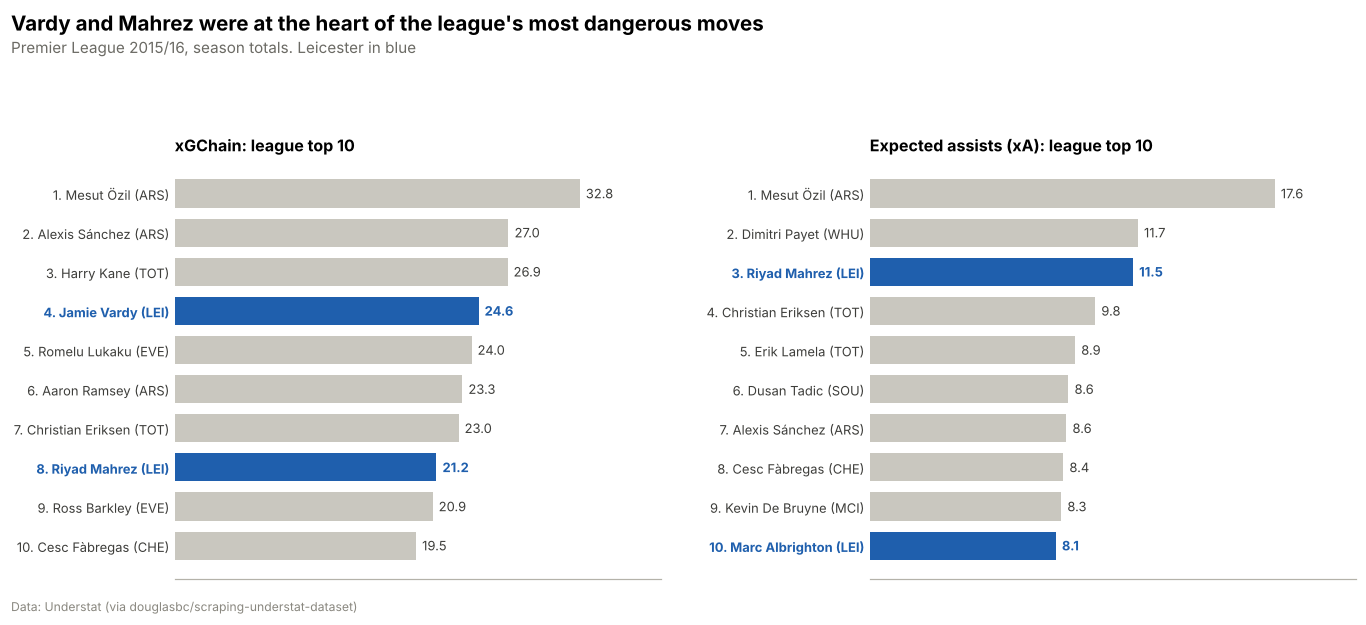

In [9]:
p = players["2015/16"].copy()
p["team"] = p.team_title.str.split(",").str[-1].str.strip()
UNDERSTAT_NAMES = {"Leicester": "Leicester City", "Tottenham": "Tottenham Hotspur", "West Ham": "West Ham United",
                   "Bournemouth": "AFC Bournemouth", "Stoke": "Stoke City", "Swansea": "Swansea City",
                   "Norwich": "Norwich City"}
p["team"] = p.team.replace(UNDERSTAT_NAMES)
p = p.set_index("id")
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
leaderboard(axes[0], p.xGChain, p.player_name, p.team, fmt="{:.1f}", title="xGChain: league top 10")
leaderboard(axes[1], p.xA, p.player_name, p.team, fmt="{:.1f}", title="Expected assists (xA): league top 10")
fig.suptitle("Vardy and Mahrez were at the heart of the league's most dangerous moves", x=0.01, ha="left",
             fontsize=13.5, fontweight="bold", y=1.06, va="bottom")
fig.text(0.01, 1.055, "Premier League 2015/16, season totals. Leicester in blue", fontsize=10, color=MUTED, va="top")
fig.tight_layout(rect=(0, 0, 1, 0.98), w_pad=3)
fig.text(0.01, -0.03, SOURCE, fontsize=8, color="#8A8880")
fig.savefig(FIGS / "28_understat_xgchain_xa.png"); plt.show()

## Summary

1. **On one consistent xG model**, Leicester went from a **15th-place team on chances (44 expected points)** to a **4th-place team (69)**. In 2014/15 they finished about where their chances deserved; in 2015/16 they beat them by 12 points.
2. **Two independent models agree** on 2015/16: Understat says 69 expected points (4th), StatsBomb 66 (4th).
3. The rolling xG chart shows **the turnaround began in the April 2015 escape** and kept going under Ranieri.
4. **Vardy's average shot quality didn't change** (0.164 → 0.161 xG per shot). He took **more than twice as many non-penalty shots** (48 → 109; 1.9 → 3.1 per 90) and went from scoring below his xG (5 from 7.9) to above it (19 from 17.6).
5. Most of the improvement came from **open play**: +0.33 xG created and −0.22 conceded per match. Penalties won added +0.18 xG per match, and set pieces conceded fell by 0.09.
6. **Vardy was 4th in the league for xGChain and Mahrez 8th. Mahrez was 3rd for expected assists and Albrighton 10th.**